In [2]:
# ==========================================
# SOLUCIONARIO: PREDICCIÓN DE FUGA DE CLIENTES (STACKING)
# ==========================================

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. CARGA DE DATOS ---
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Limpieza rápida de datos numéricos
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna()

# Convertimos la variable objetivo a binaria (1 = Se fue, 0 = Se quedó)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Seleccionamos variables numéricas rápidas
features = ['tenure', 'MonthlyCharges', 'TotalCharges']
X = df[features]
y = df['Churn']

# Separación en 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Datos listos. Entrenamiento: {X_train.shape[0]}, Prueba: {X_test.shape[0]}")

Datos listos. Entrenamiento: 5625, Prueba: 1407


In [3]:
# --- 2. ENTRENAMIENTO DE LOS MODELOS ---

# 1. Los Expertos Base (Bagging y Boosting)
bosque = RandomForestClassifier(n_estimators=100, random_state=42)
bosque.fit(X_train, y_train)

potenciado = AdaBoostClassifier(n_estimators=100, random_state=42)
potenciado.fit(X_train, y_train)

# 2. Construir el Stacking Classifier ("El Gerente")
# Lista de tuplas con los modelos entrenados
estimadores_base = [
    ('rf', bosque),        
    ('ada', potenciado)    
]

# El Stacking usa una Regresión Logística para decidir a qué experto creerle
gerente_stacking = StackingClassifier(
    estimators=estimadores_base, 
    final_estimator=LogisticRegression()
)

# Entrenar al meta-modelo
gerente_stacking.fit(X_train, y_train)

print("✅ ¡Los expertos individuales y el modelo Stacking han sido entrenados!")

✅ ¡Los expertos individuales y el modelo Stacking han sido entrenados!


In [6]:
# --- 3. EVALUACIÓN DE RESULTADOS ---
# En retención de clientes, el "Recall" es vital porque mide cuántas fugas reales logramos detectar.

def evaluar_modelo(modelo, nombre):
    predicciones = modelo.predict(X_test)
    acc = accuracy_score(y_test, predicciones)
    rec = recall_score(y_test, predicciones)
    print(f"--- {nombre} ---")
    print(f"Accuracy General: {acc*100:.1f}%")
    print(f"Recall (Detección de Fugas): {rec*100:.1f}%\n")

evaluar_modelo(bosque, "Experto 1: Random Forest (Bagging)")
evaluar_modelo(potenciado, "Experto 2: AdaBoost (Boosting)")
evaluar_modelo(gerente_stacking, "El Gerente: Stacking Classifier")

--- Experto 1: Random Forest (Bagging) ---
Accuracy General: 75.8%
Recall (Detección de Fugas): 42.2%

--- Experto 2: AdaBoost (Boosting) ---
Accuracy General: 78.1%
Recall (Detección de Fugas): 42.0%

--- El Gerente: Stacking Classifier ---
Accuracy General: 78.7%
Recall (Detección de Fugas): 40.1%



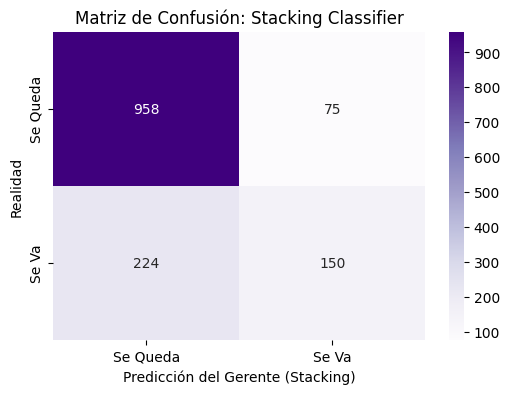

In [5]:
# --- 4. DATA STORYTELLING: MATRIZ DE CONFUSIÓN ---
# Evaluamos el rendimiento visual del modelo ganador
pred_final = gerente_stacking.predict(X_test)
matriz = confusion_matrix(y_test, pred_final)

plt.figure(figsize=(6,4))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Purples', 
            xticklabels=['Se Queda', 'Se Va'], 
            yticklabels=['Se Queda', 'Se Va'])
plt.ylabel('Realidad')
plt.xlabel('Predicción del Gerente (Stacking)')
plt.title('Matriz de Confusión: Stacking Classifier')
plt.show()